# PD — Logistic Regression

Train the interpretable baseline/champion PD model.


In [1]:
# ============================================
# PD — Logistic Regression
# Carga y preparación inicial
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Ruta del dataset
DATA_PATH = "../data/raw/cs-training.csv"

# Cargar dataset
df = pd.read_csv(DATA_PATH)

print("Dataset cargado correctamente.")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

Dataset cargado correctamente.
Filas: 150,000
Columnas: 12


In [2]:
# ============================================
# Definición del target y variables candidatas
# ============================================

TARGET = "SeriousDlqin2yrs"

features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

X = df[features].copy()
y = df[TARGET].copy()

print("Target:", TARGET)
print(f"Variables predictoras: {len(features)}")
print(f"Observaciones: {len(df):,}")

display(X.head())

Target: SeriousDlqin2yrs
Variables predictoras: 10
Observaciones: 150,000


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
# ============================================
# Train / Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:")
print(f"  Observaciones: {len(X_train):,}")
print(f"  Default rate: {y_train.mean() * 100:.2f}%")

print("\nTest:")
print(f"  Observaciones: {len(X_test):,}")
print(f"  Default rate: {y_test.mean() * 100:.2f}%")

Train:
  Observaciones: 120,000
  Default rate: 6.68%

Test:
  Observaciones: 30,000
  Default rate: 6.68%


In [4]:
# ============================================
# Preprocesamiento para Regresión Logística
# ============================================

numeric_features = features

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features)
    ],
    remainder="drop"
)

print("Preprocesamiento configurado correctamente.")
print(f"Variables numéricas: {len(numeric_features)}")

Preprocesamiento configurado correctamente.
Variables numéricas: 10


In [5]:
# ============================================
# Modelo de Regresión Logística
# ============================================

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Entrenamiento
logistic_model.fit(X_train, y_train)

print("Modelo de Regresión Logística entrenado correctamente.")

Modelo de Regresión Logística entrenado correctamente.


In [6]:
# ============================================
# Predicción de Probability of Default (PD)
# ============================================

y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]

print("Predicciones de PD generadas correctamente.")
print(f"Número de predicciones: {len(y_pred_proba):,}")
print(f"PD mínima: {y_pred_proba.min():.4f}")
print(f"PD máxima: {y_pred_proba.max():.4f}")
print(f"PD media: {y_pred_proba.mean():.4f}")

display(
    pd.DataFrame({
        "actual_default": y_test.values[:10],
        "predicted_pd": y_pred_proba[:10]
    })
)

Predicciones de PD generadas correctamente.
Número de predicciones: 30,000
PD mínima: 0.0000
PD máxima: 0.9922
PD media: 0.0670


,actual_default,predicted_pd
0,0,0.032397
1,0,0.033150
2,0,0.035471
3,0,0.037089
4,0,0.032636
5,0,0.022574
6,0,0.036266
7,1,0.594867
8,0,0.084732
9,0,0.106745


In [7]:
# ============================================
# Métricas de discriminación
# ============================================

from sklearn.metrics import roc_auc_score, roc_curve

# AUC-ROC
auc = roc_auc_score(y_test, y_pred_proba)

# Gini
gini = 2 * auc - 1

# Curva ROC
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba
)

# KS
ks = np.max(tpr - fpr)

print(f"AUC-ROC : {auc:.4f}")
print(f"Gini    : {gini:.4f}")
print(f"KS      : {ks:.4f}")

AUC-ROC : 0.7143
Gini    : 0.4287
KS      : 0.3414


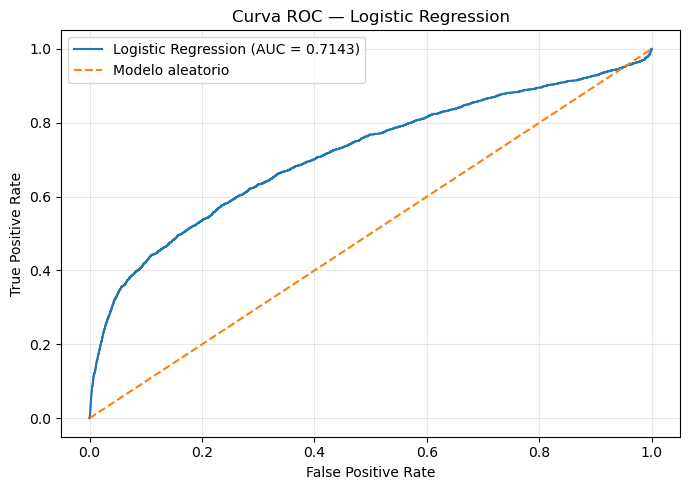

In [8]:
# ============================================
# Curva ROC
# ============================================

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Modelo aleatorio"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC — Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

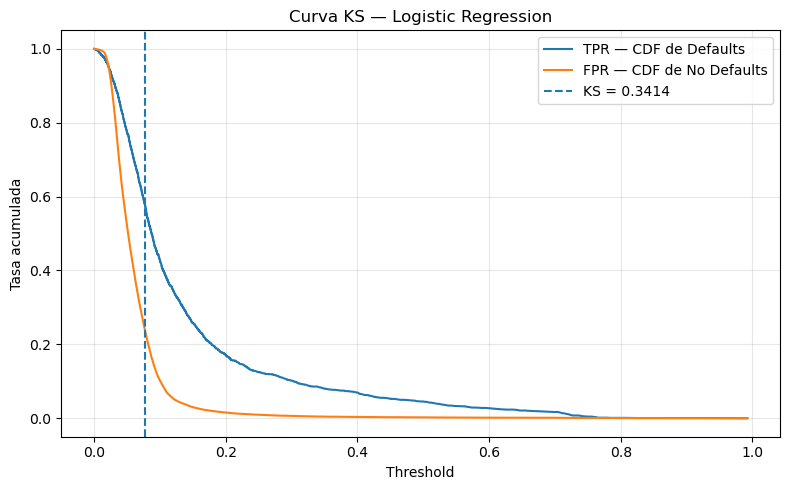

KS máximo: 0.3414
Threshold asociado al KS: 0.0777


In [9]:
# ============================================
# Curva KS
# ============================================

ks_values = tpr - fpr

ks_idx = np.argmax(ks_values)

plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    tpr,
    label="TPR — CDF de Defaults"
)

plt.plot(
    thresholds,
    fpr,
    label="FPR — CDF de No Defaults"
)

plt.axvline(
    thresholds[ks_idx],
    linestyle="--",
    label=f"KS = {ks:.4f}"
)

plt.xlabel("Threshold")
plt.ylabel("Tasa acumulada")
plt.title("Curva KS — Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"KS máximo: {ks:.4f}")
print(f"Threshold asociado al KS: {thresholds[ks_idx]:.4f}")

In [10]:
# ============================================
# Coeficientes de la Regresión Logística
# ============================================

model = logistic_model.named_steps["model"]

coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": model.coef_[0]
})

coefficients["odds_ratio"] = np.exp(
    coefficients["coefficient"]
)

coefficients["abs_coefficient"] = (
    coefficients["coefficient"].abs()
)

coefficients = (
    coefficients
    .sort_values("abs_coefficient", ascending=False)
    .drop(columns="abs_coefficient")
)

display(coefficients)

,feature,coefficient,odds_ratio
8,NumberOfTime60-89DaysPastDueNotWorse,-3.823250,0.021857
2,NumberOfTime30-59DaysPastDueNotWorse,2.052000,7.783454
6,NumberOfTimes90DaysLate,1.929054,6.882998
4,MonthlyIncome,-0.429133,0.651073
1,age,-0.402108,0.668909
9,NumberOfDependents,0.104472,1.110124
3,DebtRatio,-0.082973,0.920376
7,NumberRealEstateLoansOrLines,0.081058,1.084434
5,NumberOfOpenCreditLinesAndLoans,-0.057749,0.943887
0,RevolvingUtilizationOfUnsecuredLines,-0.003713,0.996293


In [11]:
# ============================================
# Multicolinealidad — VIF
# ============================================

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Copia de las variables predictoras
X_vif = X.copy()

# Imputación temporal para poder calcular VIF
X_vif = X_vif.fillna(X_vif.median())

vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i
        )
        for i in range(X_vif.shape[1])
    ]
})

vif = vif.sort_values(
    "VIF",
    ascending=False
)

display(vif)

,feature,VIF
8,NumberOfTime60-89DaysPastDueNotWorse,91.181441
6,NumberOfTimes90DaysLate,73.196237
2,NumberOfTime30-59DaysPastDueNotWorse,41.173243
5,NumberOfOpenCreditLinesAndLoans,4.570548
1,age,3.638439
7,NumberRealEstateLoansOrLines,2.304678
9,NumberOfDependents,1.403443
4,MonthlyIncome,1.269632
3,DebtRatio,1.049552
0,RevolvingUtilizationOfUnsecuredLines,1.000777


In [12]:
# ============================================
# Resumen del modelo Logistic Regression
# ============================================

baseline_results = pd.DataFrame({
    "model": ["Logistic Regression - Baseline"],
    "auc_roc": [auc],
    "gini": [gini],
    "ks": [ks]
})

display(baseline_results)

,model,auc_roc,gini,ks
0,Logistic Regression - Baseline,0.714328,0.428656,0.341411


In [13]:
# ============================================
# Cargar dataset con Feature Engineering
# ============================================

PROCESSED_PATH = "../data/processed/pd_features.csv"

df_fe = pd.read_csv(PROCESSED_PATH)

print("Dataset con Feature Engineering cargado correctamente.")
print(f"Filas: {df_fe.shape[0]:,}")
print(f"Columnas: {df_fe.shape[1]:,}")

Dataset con Feature Engineering cargado correctamente.
Filas: 150,000
Columnas: 48


In [14]:
# ============================================
# Selección de features con Feature Engineering
# ============================================

engineered_features = [
    "age_clean",
    "DebtRatio_clean",
    "Utilization_clean",
    "MonthlyIncome_imputed",
    "NumberOfDependents_imputed",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    
    "total_late_count",
    "max_late_count",
    "late_90plus",
    "any_late",
    "late_severity",
    "late_burden",
    
    "income_per_credit_line_clean"
]

TARGET = "SeriousDlqin2yrs"

X_fe = df_fe[engineered_features].copy()
y_fe = df_fe[TARGET].copy()

print(f"Features seleccionadas: {len(engineered_features)}")
print(f"Observaciones: {len(X_fe):,}")

display(X_fe.head())

Features seleccionadas: 14
Observaciones: 150,000


,age_clean,DebtRatio_clean,Utilization_clean,MonthlyIncome_imputed,NumberOfDependents_imputed,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,total_late_count,max_late_count,late_90plus,any_late,late_severity,late_burden,income_per_credit_line_clean
0,45.0,0.802982,0.766127,9120.0,2.0,13,6,2.0,2.0,0,1,2.0,2.0,701.538462
1,40.0,0.121876,0.957151,2600.0,1.0,4,0,0.0,0.0,0,0,0.0,0.0,650.000000
2,38.0,0.085113,0.658180,3042.0,0.0,2,0,2.0,1.0,1,1,1.0,4.0,1521.000000
3,30.0,0.036050,0.233810,3300.0,0.0,5,0,0.0,0.0,0,0,0.0,0.0,660.000000
4,49.0,0.024926,0.907239,63588.0,0.0,7,1,1.0,1.0,0,1,1.0,1.0,4600.000000


In [15]:
# ============================================
# Train / Test Split — Feature Engineering
# ============================================

X_fe_train, X_fe_test, y_fe_train, y_fe_test = train_test_split(
    X_fe,
    y_fe,
    test_size=0.20,
    random_state=42,
    stratify=y_fe
)

print("Train:")
print(f"  Observaciones: {len(X_fe_train):,}")
print(f"  Default rate: {y_fe_train.mean() * 100:.2f}%")

print("\nTest:")
print(f"  Observaciones: {len(X_fe_test):,}")
print(f"  Default rate: {y_fe_test.mean() * 100:.2f}%")

Train:
  Observaciones: 120,000
  Default rate: 6.68%

Test:
  Observaciones: 30,000
  Default rate: 6.68%


In [16]:
# ============================================
# Preprocesamiento — Feature Engineering
# ============================================

numeric_pipeline_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline_fe, engineered_features)
    ],
    remainder="drop"
)

print("Preprocesamiento FE configurado correctamente.")
print(f"Variables numéricas: {len(engineered_features)}")

Preprocesamiento FE configurado correctamente.
Variables numéricas: 14


In [17]:
# ============================================
# Regresión Logística — Feature Engineering
# ============================================

logistic_model_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Entrenamiento
logistic_model_fe.fit(
    X_fe_train,
    y_fe_train
)

print("Modelo Logistic Regression FE entrenado correctamente.")

Modelo Logistic Regression FE entrenado correctamente.


In [18]:
# ============================================
# Predicción de PD — Modelo FE
# ============================================

y_fe_pred_proba = logistic_model_fe.predict_proba(X_fe_test)[:, 1]

print("Predicciones de PD FE generadas correctamente.")
print(f"Número de predicciones: {len(y_fe_pred_proba):,}")
print(f"PD mínima: {y_fe_pred_proba.min():.4f}")
print(f"PD máxima: {y_fe_pred_proba.max():.4f}")
print(f"PD media: {y_fe_pred_proba.mean():.4f}")

Predicciones de PD FE generadas correctamente.
Número de predicciones: 30,000
PD mínima: 0.0000
PD máxima: 0.9748
PD media: 0.0666


In [19]:
# ============================================
# Métricas — Modelo FE
# ============================================

auc_fe = roc_auc_score(
    y_fe_test,
    y_fe_pred_proba
)

gini_fe = 2 * auc_fe - 1

fpr_fe, tpr_fe, thresholds_fe = roc_curve(
    y_fe_test,
    y_fe_pred_proba
)

ks_fe = np.max(tpr_fe - fpr_fe)

print(f"AUC-ROC : {auc_fe:.4f}")
print(f"Gini    : {gini_fe:.4f}")
print(f"KS      : {ks_fe:.4f}")

AUC-ROC : 0.8611
Gini    : 0.7222
KS      : 0.5642


In [20]:
# ============================================
# Comparación Baseline vs Feature Engineering
# ============================================

model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression - Baseline",
        "Logistic Regression - Feature Engineering"
    ],
    "auc_roc": [
        auc,
        auc_fe
    ],
    "gini": [
        gini,
        gini_fe
    ],
    "ks": [
        ks,
        ks_fe
    ]
})

display(model_comparison)

,model,auc_roc,gini,ks
0,Logistic Regression - Baseline,0.714328,0.428656,0.341411
1,Logistic Regression - Feature Engineering,0.861076,0.722152,0.564214


In [21]:
# ============================================
# Nota metodológica — Feature Engineering
# ============================================

print("NOTA:")
print("El modelo FE obtuvo AUC = {:.4f}, Gini = {:.4f} y KS = {:.4f}.".format(
    auc_fe,
    gini_fe,
    ks_fe
))

print(
    "\nEste resultado se considera preliminar porque "
    "algunas transformaciones del Feature Engineering "
    "fueron calculadas antes del Train/Test Split."
)

print(
    "Se realizará una validación posterior para verificar "
    "que las mejoras sean consistentes y estén libres de data leakage."
)

NOTA:
El modelo FE obtuvo AUC = 0.8611, Gini = 0.7222 y KS = 0.5642.

Este resultado se considera preliminar porque algunas transformaciones del Feature Engineering fueron calculadas antes del Train/Test Split.
Se realizará una validación posterior para verificar que las mejoras sean consistentes y estén libres de data leakage.


## Cierre — Regresión Logística

En este notebook se construyó una primera aproximación de un modelo de **Probability of Default (PD)** mediante Regresión Logística.

### Modelos evaluados

Se compararon dos especificaciones:

- **Logistic Regression — Baseline:** utiliza las variables originales seleccionadas.
- **Logistic Regression — Feature Engineering:** incorpora variables derivadas de calidad de datos, utilización, capacidad de crédito e historial de mora.

### Resultados preliminares

| Modelo | AUC-ROC | Gini | KS |
|---|---:|---:|---:|
| Logistic Regression — Baseline | 0.7143 | 0.4287 | 0.3414 |
| Logistic Regression — Feature Engineering | 0.8611 | 0.7222 | 0.5642 |

El modelo con Feature Engineering presenta una mejora importante en las métricas de discriminación respecto al baseline.

Sin embargo, estos resultados deben considerarse **preliminares**. Algunas transformaciones utilizadas en el Feature Engineering fueron calculadas antes de realizar la separación Train/Test. Por ello, en la etapa de validación se revisará el posible **data leakage** y se implementará una versión *leakage-safe* cuando corresponda.

### Próximos pasos

1. Revisar y corregir posibles fuentes de **data leakage**.
2. Validar nuevamente el modelo de Regresión Logística.
3. Analizar calibración y distribución de PD.
4. Construir el modelo **XGBoost Challenger**.
5. Comparar ambos modelos bajo las mismas métricas.
6. Continuar posteriormente con la validación y monitoreo del modelo PD.

## Validación Leakage-Safe

El modelo de Feature Engineering anterior obtuvo resultados preliminares de AUC-ROC = 0.8611, Gini = 0.7222 y KS = 0.5642.

Debido a que algunas transformaciones fueron calculadas utilizando el dataset completo antes de la separación Train/Test, se realizará una nueva construcción de las variables utilizando únicamente información disponible en el conjunto de entrenamiento.

El objetivo es evitar data leakage y obtener una estimación más rigurosa del desempeño del modelo.

In [2]:
# ============================================
# Imports — Validación Leakage-Safe
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# ============================================
# Split inicial para validación leakage-safe
# ============================================

RAW_PATH = "../data/raw/cs-training.csv"

df_raw = pd.read_csv(RAW_PATH)

TARGET = "SeriousDlqin2yrs"

X_raw = df_raw.drop(columns=[TARGET])
y_raw = df_raw[TARGET]

X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_raw
)

print("Split leakage-safe creado correctamente.")
print(f"Train: {len(X_raw_train):,}")
print(f"Test:  {len(X_raw_test):,}")
print(f"Default rate Train: {y_raw_train.mean() * 100:.2f}%")
print(f"Default rate Test:  {y_raw_test.mean() * 100:.2f}%")

Split leakage-safe creado correctamente.
Train: 120,000
Test:  30,000
Default rate Train: 6.68%
Default rate Test:  6.68%


In [4]:
# ============================================
# Parámetros de Feature Engineering aprendidos
# únicamente desde TRAIN
# ============================================

monthly_income_median_train = X_raw_train["MonthlyIncome"].median()

dependents_median_train = X_raw_train["NumberOfDependents"].median()

debt_ratio_p99_train = X_raw_train["DebtRatio"].quantile(0.99)

utilization_p99_train = (
    X_raw_train["RevolvingUtilizationOfUnsecuredLines"]
    .quantile(0.99)
)

print("Parámetros calculados exclusivamente con TRAIN:")
print(f"MonthlyIncome median: {monthly_income_median_train:.2f}")
print(f"NumberOfDependents median: {dependents_median_train:.2f}")
print(f"DebtRatio P99: {debt_ratio_p99_train:.2f}")
print(f"Utilization P99: {utilization_p99_train:.4f}")

Parámetros calculados exclusivamente con TRAIN:
MonthlyIncome median: 5390.00
NumberOfDependents median: 0.00
DebtRatio P99: 4977.00
Utilization P99: 1.0944


In [5]:
# ============================================
# Feature Engineering — Leakage-Safe
# ============================================

def build_pd_features(df, monthly_income_median, dependents_median,
                      debt_ratio_p99, utilization_p99):
    
    data = df.copy()

    # ----------------------------
    # Imputación
    # ----------------------------
    data["MonthlyIncome_imputed"] = (
        data["MonthlyIncome"]
        .fillna(monthly_income_median)
    )

    data["NumberOfDependents_imputed"] = (
        data["NumberOfDependents"]
        .fillna(dependents_median)
    )

    # ----------------------------
    # Edad
    # ----------------------------
    data["age_clean"] = data["age"].copy()

    data["age_invalid"] = (
        (data["age"] < 18) |
        (data["age"] > 100)
    ).astype(int)

    age_median = data.loc[
        ~data["age_invalid"].astype(bool),
        "age"
    ].median()

    data.loc[data["age_invalid"] == 1, "age_clean"] = age_median

    # ----------------------------
    # Debt Ratio
    # ----------------------------
    data["DebtRatio_extreme"] = (
        data["DebtRatio"] > debt_ratio_p99
    ).astype(int)

    data["DebtRatio_clean"] = (
        data["DebtRatio"]
        .clip(upper=debt_ratio_p99)
    )

    # ----------------------------
    # Utilization
    # ----------------------------
    data["Utilization_extreme"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        > utilization_p99
    ).astype(int)

    data["Utilization_clean"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        .clip(upper=utilization_p99)
    )

    # ----------------------------
    # Variables de mora
    # ----------------------------
    late_cols = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
        "NumberOfTime60-89DaysPastDueNotWorse"
    ]

    for col in late_cols:
        data[f"{col}_imputed"] = data[col].fillna(0)

    data["total_late_count"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"] +
        data["NumberOfTimes90DaysLate_imputed"] +
        data["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
    )

    data["max_late_count"] = data[
        [
            "NumberOfTime30-59DaysPastDueNotWorse_imputed",
            "NumberOfTimes90DaysLate_imputed",
            "NumberOfTime60-89DaysPastDueNotWorse_imputed"
        ]
    ].max(axis=1)

    data["late_90plus"] = (
        data["NumberOfTimes90DaysLate_imputed"] > 0
    ).astype(int)

    data["any_late"] = (
        data["total_late_count"] > 0
    ).astype(int)

    # ----------------------------
    # Severidad de mora
    # ----------------------------
    data["late_severity"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"] * 1
        + data["NumberOfTime60-89DaysPastDueNotWorse_imputed"] * 2
        + data["NumberOfTimes90DaysLate_imputed"] * 3
    )

    data["late_burden"] = (
        data["total_late_count"] * data["late_severity"]
    )

    # ----------------------------
    # Capacidad de crédito
    # ----------------------------
    data["income_per_credit_line"] = (
        data["MonthlyIncome_imputed"] /
        data["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
    )

    income_credit_median = data["income_per_credit_line"].median()

    data["income_per_credit_line_clean"] = (
        data["income_per_credit_line"]
        .fillna(income_credit_median)
        .clip(upper=data["income_per_credit_line"].quantile(0.99))
    )

    return data

In [6]:
# ============================================
# Aplicar Feature Engineering a Train y Test
# ============================================

train_fe = build_pd_features(
    X_raw_train,
    monthly_income_median_train,
    dependents_median_train,
    debt_ratio_p99_train,
    utilization_p99_train
)

test_fe = build_pd_features(
    X_raw_test,
    monthly_income_median_train,
    dependents_median_train,
    debt_ratio_p99_train,
    utilization_p99_train
)

print("Feature Engineering aplicado correctamente.")
print(f"Train: {train_fe.shape[0]:,} filas | {train_fe.shape[1]:,} columnas")
print(f"Test:  {test_fe.shape[0]:,} filas | {test_fe.shape[1]:,} columnas")

Feature Engineering aplicado correctamente.
Train: 120,000 filas | 30 columnas
Test:  30,000 filas | 30 columnas


In [7]:
# ============================================
# Verificación de Train / Test
# ============================================

print("¿Mismas columnas?")
print(train_fe.columns.equals(test_fe.columns))

print("\nValores faltantes en TRAIN:")
print(train_fe.isna().sum().sum())

print("\nValores faltantes en TEST:")
print(test_fe.isna().sum().sum())

print("\nVariables principales:")
display(
    train_fe[
        [
            "age_clean",
            "DebtRatio_clean",
            "Utilization_clean",
            "MonthlyIncome_imputed",
            "NumberOfDependents_imputed",
            "total_late_count",
            "max_late_count",
            "late_90plus",
            "any_late",
            "late_severity",
            "late_burden",
            "income_per_credit_line_clean"
        ]
    ].head()
)

¿Mismas columnas?
True

Valores faltantes en TRAIN:
28304

Valores faltantes en TEST:
7239

Variables principales:


,age_clean,DebtRatio_clean,Utilization_clean,MonthlyIncome_imputed,NumberOfDependents_imputed,total_late_count,max_late_count,late_90plus,any_late,late_severity,late_burden,income_per_credit_line_clean
57836,62,1841.000000,0.114987,5390.0,2.0,0,0,0,0,0,0,1078.000000
132895,73,0.498553,0.008705,3800.0,0.0,0,0,0,0,0,0,633.333333
27981,32,0.211999,0.214501,3716.0,2.0,0,0,0,0,0,0,464.500000
37852,60,118.000000,1.000000,5390.0,0.0,0,0,0,0,0,0,1078.000000
103813,60,1.017328,0.230493,3000.0,0.0,0,0,0,0,0,0,300.000000


In [8]:
# ============================================
# Diagnóstico de valores faltantes
# ============================================

missing_train = (
    train_fe.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_test = (
    test_fe.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_check = pd.DataFrame({
    "missing_train": missing_train,
    "missing_test": missing_test
})

display(
    missing_check[
        (missing_check["missing_train"] > 0) |
        (missing_check["missing_test"] > 0)
    ]
)

,missing_train,missing_test
MonthlyIncome,23675,6056
NumberOfDependents,3128,796
income_per_credit_line,1501,387


In [9]:
# ============================================
# Parámetros adicionales aprendidos de TRAIN
# ============================================

# Edad válida
age_invalid_train = (
    (X_raw_train["age"] < 18) |
    (X_raw_train["age"] > 100)
)

age_median_train = X_raw_train.loc[
    ~age_invalid_train,
    "age"
].median()

# Income per credit line
monthly_income_train = (
    X_raw_train["MonthlyIncome"]
    .fillna(monthly_income_median_train)
)

credit_lines_train = X_raw_train[
    "NumberOfOpenCreditLinesAndLoans"
]

income_per_credit_line_train = (
    monthly_income_train /
    credit_lines_train.replace(0, np.nan)
)

income_credit_median_train = (
    income_per_credit_line_train
    .median()
)

income_credit_p99_train = (
    income_per_credit_line_train
    .quantile(0.99)
)

print("Parámetros adicionales calculados exclusivamente con TRAIN:")
print(f"Age median: {age_median_train:.2f}")
print(f"Income per credit line median: {income_credit_median_train:.2f}")
print(f"Income per credit line P99: {income_credit_p99_train:.2f}")

Parámetros adicionales calculados exclusivamente con TRAIN:
Age median: 52.00
Income per credit line median: 722.22
Income per credit line P99: 5390.00


In [10]:
# ============================================
# Feature Engineering — versión leakage-safe
# ============================================

def build_pd_features_safe(
    df,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
):
    
    data = df.copy()

    # ----------------------------
    # Imputación
    # ----------------------------
    data["MonthlyIncome_imputed"] = (
        data["MonthlyIncome"]
        .fillna(monthly_income_median)
    )

    data["NumberOfDependents_imputed"] = (
        data["NumberOfDependents"]
        .fillna(dependents_median)
    )

    # ----------------------------
    # Edad
    # ----------------------------
    data["age_invalid"] = (
        (data["age"] < 18) |
        (data["age"] > 100)
    ).astype(int)

    data["age_clean"] = (
        data["age"]
        .where(data["age_invalid"] == 0, age_median)
    )

    # ----------------------------
    # Debt Ratio
    # ----------------------------
    data["DebtRatio_extreme"] = (
        data["DebtRatio"] > debt_ratio_p99
    ).astype(int)

    data["DebtRatio_clean"] = (
        data["DebtRatio"]
        .clip(upper=debt_ratio_p99)
    )

    # ----------------------------
    # Utilization
    # ----------------------------
    data["Utilization_extreme"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        > utilization_p99
    ).astype(int)

    data["Utilization_clean"] = (
        data["RevolvingUtilizationOfUnsecuredLines"]
        .clip(upper=utilization_p99)
    )

    # ----------------------------
    # Variables de mora
    # ----------------------------
    late_cols = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
        "NumberOfTime60-89DaysPastDueNotWorse"
    ]

    for col in late_cols:
        data[f"{col}_imputed"] = data[col].fillna(0)

    data["total_late_count"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"]
        + data["NumberOfTimes90DaysLate_imputed"]
        + data["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
    )

    data["max_late_count"] = data[
        [
            "NumberOfTime30-59DaysPastDueNotWorse_imputed",
            "NumberOfTimes90DaysLate_imputed",
            "NumberOfTime60-89DaysPastDueNotWorse_imputed"
        ]
    ].max(axis=1)

    data["late_90plus"] = (
        data["NumberOfTimes90DaysLate_imputed"] > 0
    ).astype(int)

    data["any_late"] = (
        data["total_late_count"] > 0
    ).astype(int)

    # ----------------------------
    # Severidad de mora
    # ----------------------------
    data["late_severity"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse_imputed"] * 1
        + data["NumberOfTime60-89DaysPastDueNotWorse_imputed"] * 2
        + data["NumberOfTimes90DaysLate_imputed"] * 3
    )

    data["late_burden"] = (
        data["total_late_count"]
        * data["late_severity"]
    )

    # ----------------------------
    # Capacidad de crédito
    # ----------------------------
    data["income_per_credit_line"] = (
        data["MonthlyIncome_imputed"]
        / data["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
    )

    data["income_per_credit_line_clean"] = (
        data["income_per_credit_line"]
        .fillna(income_credit_median)
        .clip(upper=income_credit_p99)
    )

    return data

In [11]:
# ============================================
# Aplicar Feature Engineering Leakage-Safe
# ============================================

train_fe_safe = build_pd_features_safe(
    X_raw_train,
    monthly_income_median_train,
    dependents_median_train,
    age_median_train,
    debt_ratio_p99_train,
    utilization_p99_train,
    income_credit_median_train,
    income_credit_p99_train
)

test_fe_safe = build_pd_features_safe(
    X_raw_test,
    monthly_income_median_train,
    dependents_median_train,
    age_median_train,
    debt_ratio_p99_train,
    utilization_p99_train,
    income_credit_median_train,
    income_credit_p99_train
)

print("Feature Engineering Leakage-Safe aplicado correctamente.")
print(f"Train: {train_fe_safe.shape[0]:,} filas | {train_fe_safe.shape[1]:,} columnas")
print(f"Test:  {test_fe_safe.shape[0]:,} filas | {test_fe_safe.shape[1]:,} columnas")

Feature Engineering Leakage-Safe aplicado correctamente.
Train: 120,000 filas | 30 columnas
Test:  30,000 filas | 30 columnas


In [12]:
# ============================================
# Verificación final — Leakage-Safe
# ============================================

missing_train_safe = train_fe_safe.isna().sum()
missing_test_safe = test_fe_safe.isna().sum()

missing_safe = pd.DataFrame({
    "missing_train": missing_train_safe,
    "missing_test": missing_test_safe
})

display(
    missing_safe[
        (missing_safe["missing_train"] > 0) |
        (missing_safe["missing_test"] > 0)
    ]
)

print(f"Total NaN en TRAIN: {train_fe_safe.isna().sum().sum():,}")
print(f"Total NaN en TEST:  {test_fe_safe.isna().sum().sum():,}")

,missing_train,missing_test
MonthlyIncome,23675,6056
NumberOfDependents,3128,796
income_per_credit_line,1501,387


Total NaN en TRAIN: 28,304
Total NaN en TEST:  7,239


In [13]:
# ============================================
# Verificación de features utilizadas por el modelo
# ============================================

safe_features = [
    "age_clean",
    "DebtRatio_clean",
    "Utilization_clean",
    "MonthlyIncome_imputed",
    "NumberOfDependents_imputed",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "total_late_count",
    "max_late_count",
    "late_90plus",
    "any_late",
    "late_severity",
    "late_burden",
    "income_per_credit_line_clean"
]

safe_missing = pd.DataFrame({
    "missing_train": train_fe_safe[safe_features].isna().sum(),
    "missing_test": test_fe_safe[safe_features].isna().sum()
})

display(
    safe_missing[
        (safe_missing["missing_train"] > 0) |
        (safe_missing["missing_test"] > 0)
    ]
)

print(
    f"NaN en features del modelo - TRAIN: "
    f"{train_fe_safe[safe_features].isna().sum().sum():,}"
)

print(
    f"NaN en features del modelo - TEST: "
    f"{test_fe_safe[safe_features].isna().sum().sum():,}"
)

,missing_train,missing_test


NaN en features del modelo - TRAIN: 0
NaN en features del modelo - TEST: 0


In [14]:
# ============================================
# Dataset final para Logistic Regression
# ============================================

X_safe_train = train_fe_safe[safe_features].copy()
X_safe_test = test_fe_safe[safe_features].copy()

y_safe_train = y_raw_train.copy()
y_safe_test = y_raw_test.copy()

print("Dataset final preparado correctamente.")
print(f"Train: {X_safe_train.shape[0]:,} filas | {X_safe_train.shape[1]} features")
print(f"Test:  {X_safe_test.shape[0]:,} filas | {X_safe_test.shape[1]} features")

Dataset final preparado correctamente.
Train: 120,000 filas | 14 features
Test:  30,000 filas | 14 features


In [16]:
# ============================================
# Imports para Logistic Regression Leakage-Safe
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("Componentes de sklearn cargados correctamente.")

Componentes de sklearn cargados correctamente.


In [17]:
# ============================================
# Logistic Regression — Leakage-Safe
# ============================================

numeric_pipeline_safe = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

preprocessor_safe = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline_safe, safe_features)
    ],
    remainder="drop"
)

logistic_model_safe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_safe),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model_safe.fit(
    X_safe_train,
    y_safe_train
)

print("Logistic Regression Leakage-Safe entrenado correctamente.")

Logistic Regression Leakage-Safe entrenado correctamente.


In [18]:
# ============================================
# Predicciones de PD — Leakage-Safe
# ============================================

y_safe_pred_proba = logistic_model_safe.predict_proba(
    X_safe_test
)[:, 1]

print("Predicciones de PD Leakage-Safe generadas correctamente.")
print(f"Número de predicciones: {len(y_safe_pred_proba):,}")
print(f"PD mínima: {y_safe_pred_proba.min():.4f}")
print(f"PD máxima: {y_safe_pred_proba.max():.4f}")
print(f"PD media: {y_safe_pred_proba.mean():.4f}")

Predicciones de PD Leakage-Safe generadas correctamente.
Número de predicciones: 30,000
PD mínima: 0.0000
PD máxima: 0.9812
PD media: 0.0667


In [19]:
# ============================================
# Métricas definitivas — Leakage-Safe
# ============================================

from sklearn.metrics import roc_auc_score, roc_curve

auc_safe = roc_auc_score(
    y_safe_test,
    y_safe_pred_proba
)

gini_safe = 2 * auc_safe - 1

fpr_safe, tpr_safe, thresholds_safe = roc_curve(
    y_safe_test,
    y_safe_pred_proba
)

ks_values_safe = tpr_safe - fpr_safe
ks_safe = np.max(ks_values_safe)

ks_safe_idx = np.argmax(ks_values_safe)
ks_safe_threshold = thresholds_safe[ks_safe_idx]

print(f"AUC-ROC : {auc_safe:.4f}")
print(f"Gini    : {gini_safe:.4f}")
print(f"KS      : {ks_safe:.4f}")
print(f"Threshold asociado al KS: {ks_safe_threshold:.4f}")

AUC-ROC : 0.8628
Gini    : 0.7257
KS      : 0.5685
Threshold asociado al KS: 0.0589


In [21]:
# Import para visualización

import matplotlib.pyplot as plt

print("Matplotlib cargado correctamente.")

Matplotlib cargado correctamente.


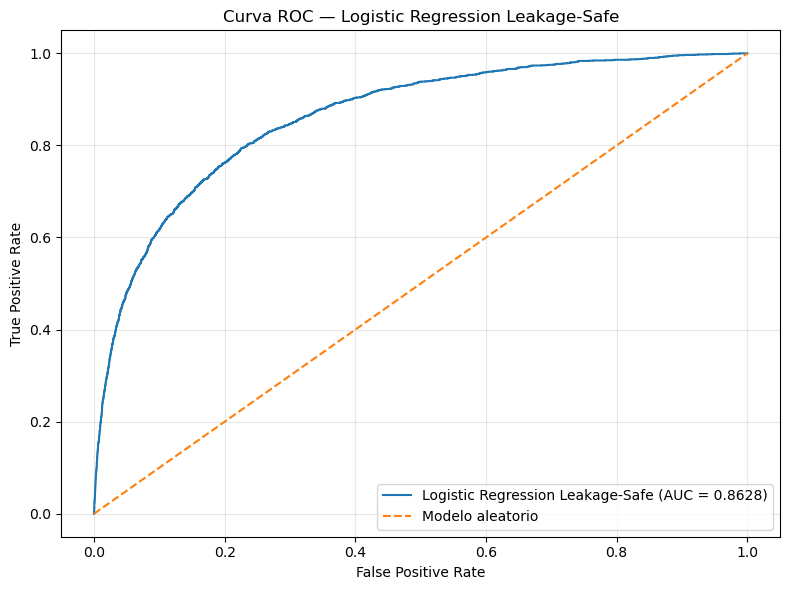

In [22]:
# ============================================
# Curva ROC — Logistic Regression Leakage-Safe
# ============================================

fpr_roc_safe, tpr_roc_safe, _ = roc_curve(
    y_safe_test,
    y_safe_pred_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_roc_safe,
    tpr_roc_safe,
    label=f"Logistic Regression Leakage-Safe (AUC = {auc_safe:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Modelo aleatorio"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC — Logistic Regression Leakage-Safe")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

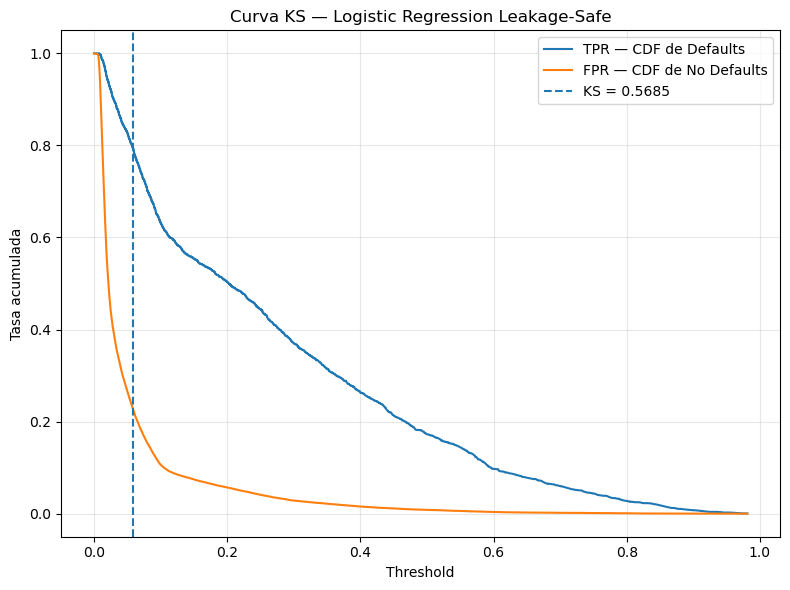

KS máximo: 0.5685
Threshold asociado al KS: 0.0589


In [23]:
# ============================================
# Curva KS — Logistic Regression Leakage-Safe
# ============================================

thresholds_plot = thresholds_safe

plt.figure(figsize=(8, 6))

plt.plot(
    thresholds_plot,
    tpr_safe,
    label="TPR — CDF de Defaults"
)

plt.plot(
    thresholds_plot,
    fpr_safe,
    label="FPR — CDF de No Defaults"
)

plt.axvline(
    ks_safe_threshold,
    linestyle="--",
    label=f"KS = {ks_safe:.4f}"
)

plt.xlabel("Threshold")
plt.ylabel("Tasa acumulada")
plt.title("Curva KS — Logistic Regression Leakage-Safe")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"KS máximo: {ks_safe:.4f}")
print(f"Threshold asociado al KS: {ks_safe_threshold:.4f}")

In [25]:
# ============================================
# Comparación final — Modelos Logistic Regression
# ============================================

final_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression - Baseline",
        "Logistic Regression - Feature Engineering (Preliminar)",
        "Logistic Regression - Feature Engineering (Leakage-Safe)"
    ],
    "auc_roc": [
        0.714328,
        0.861076,
        auc_safe
    ],
    "gini": [
        0.428656,
        0.722152,
        gini_safe
    ],
    "ks": [
        0.341411,
        0.564214,
        ks_safe
    ]
})

display(final_comparison)

,model,auc_roc,gini,ks
0,Logistic Regression - Baseline,0.714328,0.428656,0.341411
1,Logistic Regression - Feature Engineering (Pre...,0.861076,0.722152,0.564214
2,Logistic Regression - Feature Engineering (Lea...,0.862847,0.725695,0.568547


## Cierre — Regresión Logística

En este notebook se desarrolló y evaluó un modelo de **Probability of Default (PD)** mediante Regresión Logística.

Se evaluaron tres etapas:

1. **Baseline:** modelo con variables originales.
2. **Feature Engineering preliminar:** incorporación de variables derivadas de calidad de datos, historial de mora, utilización y capacidad de crédito.
3. **Feature Engineering Leakage-Safe:** reconstrucción de las transformaciones utilizando parámetros calculados exclusivamente sobre el conjunto de entrenamiento.

### Resultados

| Modelo | AUC-ROC | Gini | KS |
|---|---:|---:|---:|
| Logistic Regression — Baseline | 0.7143 | 0.4287 | 0.3414 |
| Logistic Regression — Feature Engineering (Preliminar) | 0.8611 | 0.7222 | 0.5642 |
| Logistic Regression — Feature Engineering (Leakage-Safe) | **0.8628** | **0.7257** | **0.5685** |

### Interpretación

El Feature Engineering produjo una mejora sustancial respecto al modelo baseline.

La versión *leakage-safe* obtuvo un **AUC-ROC de 0.8628**, un **Gini de 0.7257** y un **KS de 0.5685**.

El desempeño se mantuvo prácticamente igual respecto al resultado preliminar, lo que indica que la mejora observada no depende de una fuente relevante de **data leakage**.

El threshold asociado al máximo KS fue aproximadamente **0.0589**.

### Consideraciones metodológicas

Para evitar contaminación entre Train y Test, las estadísticas utilizadas para las transformaciones fueron calculadas exclusivamente sobre Train y posteriormente aplicadas tanto a Train como a Test.

Entre los parámetros aprendidos únicamente de Train se incluyen:

- Mediana de `MonthlyIncome`
- Mediana de `NumberOfDependents`
- Mediana de `age`
- P99 de `DebtRatio`
- P99 de `RevolvingUtilizationOfUnsecuredLines`
- Mediana de `income_per_credit_line`
- P99 de `income_per_credit_line`

### Conclusión

La **Regresión Logística con Feature Engineering Leakage-Safe** queda establecida como el modelo base/champion interpretable para la siguiente etapa del proyecto.

El siguiente paso será desarrollar un modelo **XGBoost Challenger** y compararlo bajo las mismas métricas de discriminación.